# Phase 04 · Notebook 1: auditory encoding

## From the courtship song to spike trains on the neurons of Johnston's organ

This notebook builds the input that every network of the modeling phase receives. It has to be **identical** for all of them. If the stimulus favored one wiring, the comparison would measure nothing. We organize the project by the phases of CRISP-DM (Chapman et al., 2000). This is the modeling phase, which in the KDD process corresponds to data mining (Fayyad et al., 1996).

The chain follows the path of a sound through the auditory periphery.

```
pulse song → gammatone filterbank → inner-hair-cell stage
           → instantaneous rate per channel → inhomogeneous Poisson process → spikes on the JO neurons
```

We check every link with a measurement instead of taking it on trust.

### Background for readers new to the project

The fruit fly *Drosophila melanogaster* hears with **Johnston's organ** (JO), a set of sensory neurons in its antenna. Phase 02 extracted the circuit of those neurons from the FlyWire **connectome**, the map of all the neurons of the fly brain and of the connections between them (Dorkenwald et al., 2024). Only 123 of its JO neurons send connections onward. They form the **input layer**, the neurons that receive the sound.

The sound is the **courtship song**. A male courts by vibrating one wing, which produces a train of brief clicks, the song pulses. The time from one song pulse to the next is the **inter-pulse interval** (IPI), one of the main cues a female uses to recognize males of her own species (Bennet-Clark & Ewing, 1969). Our task asks a network to tell apart five songs that differ only in their IPI.

A **spiking neural network** (SNN) is a network whose neurons communicate with brief electrical events called **spikes**. **Spike encoding** is the step that turns a sound into spikes for the input layer, and it is what this notebook builds. Two stages do most of the work. A **gammatone filterbank** splits the sound into frequency bands, as an ear does (Section 2). An **inner-hair-cell model** then turns the vibration of each band into a firing rate (Section 3). The name comes from the mammalian ear, where inner hair cells play that role. The fly has no cochlea, so the model borrows the processing steps, not the anatomy.

The later notebooks feed these spikes into networks of **leaky integrate-and-fire** (LIF) neurons with **three synaptic channels**. Each neuron adds up the current it receives through an excitatory, an inhibitory and a modulatory channel, each with its own decay time. It leaks that charge slowly and fires a spike when its voltage crosses a threshold. The networks can learn with **spike-timing-dependent plasticity** (STDP), a local rule that strengthens a connection when the sending neuron fires just before the receiving one and weakens it when it fires just after (Song et al., 2000). A pool of inhibitory neurons provides **winner-take-all** (WTA) inhibition. It holds the network back when many neurons fire together, so that a few of them specialize.

A network is scored with a **linear readout**, a logistic regression that learns to name the song from how many spikes each neuron fired. With five songs, guessing gives a **chance level** of 0.200. The **input-only ceiling** is the accuracy of the same readout applied to the input layer itself, with no network in between. Whatever a network achieves above that ceiling is computation done by the network. Section 5 measures it.

Three wirings (the connectome and two random controls), each with and without plasticity, make six experimental **arms**. Every arm runs with several **seeds**, the numbers that fix the random generators so that a run can be repeated exactly. A **paired comparison** sets two arms side by side on the same seeds, so that only the factor under study changes. The **effect size**, Cohen's d, expresses a difference between two arms in units of their standard deviation (Cohen, 1988/2013). The **spikes per correct classification**, all the spikes the network fires during the test divided by the number of correct answers, measure what each answer costs. These notions come into play from notebook 2 onward. This notebook builds only the stimulus.

## 0. Environment

The cell sets the plotting style and prints the encoding parameters. These are the sampling rate, the duration of each stimulus and the 32 center frequencies of the filterbank, evenly spaced on the ERB scale explained in Section 2.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import freqz, gammatone

sys.path.insert(0, str(Path.cwd().parent))
from snnlib import audio as A, graph, FIGURES

FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':150,'savefig.bbox':'tight',
                     'axes.titleweight':'bold','font.size':10})
BLUE, RED, GREEN, PURPLE = '#2E86AB','#C73E1D','#3CAEA3','#7B68A6'

print(f'Sampling rate: {A.SR} Hz | duration: {A.DURATION*1000:.0f} ms')
print(f'Filterbank: {A.N_CHANNELS} channels between {A.F_MIN:.0f} and {A.F_MAX:.0f} Hz (ERB scale)')
print('Center frequencies (Hz):')
print(np.array2string(A.CF, precision=1, separator=', '))

Sampling rate: 44100 Hz | duration: 500 ms
Filterbank: 32 channels between 80 and 380 Hz (ERB scale)
Center frequencies (Hz):
[ 80. ,  86.8,  93.8, 101. , 108.3, 115.7, 123.4, 131.2, 139.1, 147.3,
 155.6, 164.1, 172.8, 181.7, 190.8, 200.1, 209.6, 219.3, 229.2, 239.3,
 249.7, 260.3, 271.1, 282.2, 293.5, 305. , 316.9, 328.9, 341.3, 353.9,
 366.8, 380. ]


## 1. The stimuli: the courtship song

The *D. melanogaster* male courts with a pulse song, and the inter-pulse interval is one of the main cues the female uses to recognize her species. It is about 34 ms in *D. melanogaster* and about 48 ms in the sister species *D. simulans* (Bennet-Clark & Ewing, 1969; Kyriacou & Hall, 1980). Deutsch et al. (2019) report ranges of 30–45 ms and 50–65 ms. Our 35 ms class is typical of *D. melanogaster*, and our 55 ms class falls in the range reported for *D. simulans*.

Our network covers only the first stage of the song pathway, the JO neurons and their direct partners. In the fly, selectivity for the species-specific interval shows up further downstream, in central neurons such as pC1, pC2l and vpoEN (Baker et al., 2022; Zhou et al., 2015). Classifying the interval is therefore a proxy task that we impose on an early-stage circuit. It is not a function known to happen there.

The network has to say which of five intervals is playing: 25, 35, 45, 55 or 65 ms. All five songs share the carrier (250 Hz), the width of each song pulse (10 ms) and the expected number of input spikes. **Only the rhythm tells them apart.**

### Why the task changed

An earlier version of the project asked the networks to tell six pure tones apart. When we measured how much information was already in the input layer, the 123 JO neurons alone classified the tones perfectly, in the same window used to compare the networks. With that ceiling no wiring could add anything. The differences between networks measured which one degraded the signal least, not which one computed best. Section 5 repeats that check for the song task, and every experiment now reports its input-only ceiling.

Carrier: 250 Hz | pulse width: 10 ms | jitter: 2 ms
Inter-pulse intervals (classes): [25, 35, 45, 55, 65] ms   ->  chance = 0.200

  IPI 25 ms: 20 song pulses in 500 ms
  IPI 35 ms: 14 song pulses in 500 ms   <- typical of D. melanogaster
  IPI 45 ms: 11 song pulses in 500 ms
  IPI 55 ms:  9 song pulses in 500 ms   <- in the range of D. simulans
  IPI 65 ms:  7 song pulses in 500 ms

Difficulty gradient (ordered by RELATIVE difference, Weber's law):
  Very easy      25 vs 65 ms  ->  40 ms apart  =  160 % of the shorter interval
  Easy           25 vs 55 ms  ->  30 ms apart  =  120 % of the shorter interval
  Medium         35 vs 55 ms  ->  20 ms apart  =   57 % of the shorter interval
  Hard           35 vs 45 ms  ->  10 ms apart  =   29 % of the shorter interval
  Very hard      45 vs 55 ms  ->  10 ms apart  =   22 % of the shorter interval


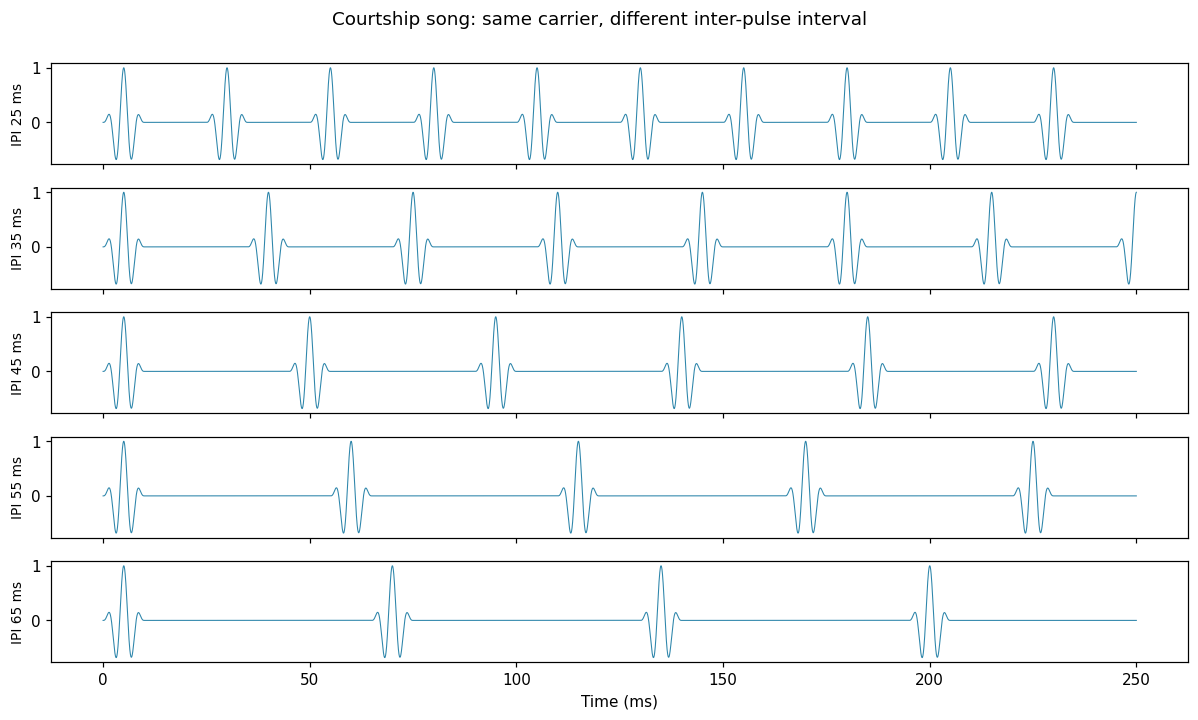

In [2]:
from snnlib.evaluation import IPIS, PAIRS, JITTER_MS
print(f'Carrier: {A.SONG_CARRIER_HZ:.0f} Hz | pulse width: {A.PULSE_WIDTH_MS:.0f} ms '
      f'| jitter: {JITTER_MS:.0f} ms')
print(f'Inter-pulse intervals (classes): {IPIS} ms   ->  chance = {1/len(IPIS):.3f}\n')
for ipi in IPIS:
    print(f'  IPI {ipi:2d} ms: {int(A.DURATION*1000/ipi):2d} song pulses in {A.DURATION*1000:.0f} ms'
          + ('   <- typical of D. melanogaster' if ipi==35 else
             '   <- in the range of D. simulans' if ipi==55 else ''))
print("\nDifficulty gradient (ordered by RELATIVE difference, Weber's law):")
for name, a_, b_ in PAIRS:
    d_ = abs(b_ - a_)
    print(f'  {name:14s} {a_} vs {b_} ms  ->  {d_} ms apart'
          f'  =  {100*d_/min(a_, b_):3.0f} % of the shorter interval')

fig, ax = plt.subplots(len(IPIS), 1, figsize=(11, 6.5), sharex=True, sharey=True)
for a, ipi in zip(ax, IPIS):
    x = A.pulse_song(ipi)
    t_ms = 1000*np.arange(len(x))/A.SR
    m = t_ms <= 250
    a.plot(t_ms[m], x[m], lw=.7, color=BLUE)
    a.set_ylabel(f'IPI {ipi} ms', fontsize=9)
ax[-1].set_xlabel('Time (ms)')
fig.suptitle('Courtship song: same carrier, different inter-pulse interval', y=1.0)
fig.tight_layout(); fig.savefig(FIGURES/'04-courtship-song-stimuli.png'); plt.show()

The printout lists how many song pulses fit in the 500 ms of each stimulus, from 20 at 25 ms down to 7 at 65 ms. It then lists the five pairs of songs used later for the two-class **difficulty gradient**, where the readout only has to choose between two songs. For each pair it gives the difference in milliseconds and as a percentage of the shorter interval, from 160 % for the easiest pair through 120 %, 57 % and 29 % down to 22 %. The figure shows the first 250 ms of each song. The clicks are identical and only their spacing changes.

**Why `Hard` and `Very hard` are 10 ms apart and still do not cost the same.** Both pairs differ by 10 ms. What changes is the base. Ten milliseconds on an interval of 35 ms is a 29 % change, and on one of 45 ms only 22 %. What a sensory system registers of a change is its proportion, not its absolute size. This is Weber's law, which also holds for timing in animals (Gibbon, 1977). That is why the series runs from 160 % down to 22 % even though the last two pairs tie in milliseconds.

The later notebooks bear this out in four of the six arms, where 45 vs 55 ms comes out worse than 35 vs 45 ms. The two Erdős–Rényi arms are the exception. They stay far below the other four on both pairs, and there the two hard pairs come out about equal.

## 2. The gammatone filterbank: an artificial ear

### What we are building

The network does not receive a sound wave. It receives what an ear hands over, and an ear does not pick up "a sound". It **splits it into frequency bands**. In the mammalian cochlea, the basilar membrane is a strip that vibrates at a different point for each pitch, and each point responds only to a narrow band around its own frequency.

We copy that with **32 channels** tuned between 80 and 380 Hz and spaced on the ERB scale. Picture **32 tuning forks**. When the song plays, each fork vibrates according to how much of *its* note the signal contains. Fly song has a sine mode around 150 Hz and pulses with carriers of roughly 200 to 450 Hz (Clemens et al., 2018; Deutsch et al., 2019). Our 250 Hz carrier lies in the pulse range. The 80–380 Hz span of the filterbank is a design choice that covers it, with margin below.

A useful tuning fork is **selective**. It vibrates with its own note and little else. A poor one vibrates with almost anything, and then it tells us nothing, because all the forks vibrate together.

> **Bandwidth (BW)**: how many hertz around its note make a channel vibrate. **Close to the ERB is right; too wide is the usual failure.**
>
> **ERB** (*equivalent rectangular bandwidth*): the bandwidth an auditory filter **should** have, measured in human listeners (Glasberg & Moore, 1990). It is the answer each channel should give. It grows with frequency, from 33.3 Hz at 80 Hz to 65.7 Hz at 380 Hz. These are human values, not fly values. We use them because the filterbank is a model of an auditory periphery, not a model of the fly's ear.

### How we implement it, and why we do not use the ready-made functions

We use the fourth-order **gammatone** filter, a widely used model of the human auditory filter (Patterson et al., 1992).

$$h(t) = \underbrace{t^{n-1} e^{-2\pi b\,\mathrm{ERB}(f_c)\,t}}_{\text{envelope: rises and decays}} \cdot \underbrace{\cos(2\pi f_c t)}_{\text{the channel's note}}$$

Here $n = 4$ is the order, $f_c$ the center frequency of the channel and $b = 1.019$ the factor that gives a fourth-order gammatone the same equivalent rectangular bandwidth as the ERB (Holdsworth et al., 1988; Slaney, 1993).

The key is the decay. **A low channel oscillates slowly and needs more time to decide whether its note is playing.** If it gets less time than it needs, the filter becomes clumsy and its band widens. We therefore compute each channel's response analytically **with the length it needs**, eight time constants, which comes to 37.5 ms at 80 Hz and 19.0 ms at 380 Hz. The two functions that SciPy provides (Virtanen et al., 2020) are more convenient, and neither works in this band.

The next three cells check exactly that. There is no parameter to tune; we measure and discard.

| Cell | What it checks | What to look at |
|---|---|---|
| table 1 | does each implementation get the right bandwidth? | compare **BW** with the **theoretical ERB**, which is the answer |
| table 2 | is the IIR variant stable? | **max \|pole\|**: above 1, the filter runs out of control |
| figure | both things, drawn | narrow, separate peaks against wide, overlapping ones |

### Why it matters

The artificial ear sets **the limit of what any network can tell apart**. If the input arrives blurred, comparing the connectome with the random network measures how much the ear spoiled the signal, not whether the wiring is of any use. Both networks would receive the same mush. This is why the filterbank had to be rebuilt (see the [research log](research-log.md) of this phase).

In [3]:
print('Impulse-response length and measured bandwidth:\n')
print(f'{"fc (Hz)":>8}{"samples":>10}{"ms":>7}{"BW analytic":>14}{"BW scipy FIR":>14}{"ERB theory":>13}')
rows=[]
for fc in [80,120,180,250,320,380]:
    h = A.impulse_response(fc)
    w,H = freqz(h, worN=65536, fs=A.SR); m=np.abs(H)/np.abs(H).max()
    bw = np.ptp(w[m>=10**(-3/20)])
    b,a = gammatone(fc, ftype='fir', fs=A.SR, order=4)
    w2,H2 = freqz(b,a,worN=65536,fs=A.SR); m2=np.abs(H2)/np.abs(H2).max()
    bw_fir = np.ptp(w2[m2>=10**(-3/20)])
    erb = float(A.theoretical_erb(fc))
    rows.append((fc,len(h),bw,bw_fir,erb))
    print(f'{fc:8d}{len(h):10d}{1000*len(h)/A.SR:7.1f}{bw:12.1f} Hz{bw_fir:12.1f} Hz{erb:11.1f} Hz')
print()
print('The analytic filterbank matches the theoretical ERB within 1 Hz over the whole range.')
print('The scipy FIR gives 78.4-86.5 Hz in EVERY channel: at 80 Hz that is 2.5 times')
print('wider than it should be, and the low channels are no longer separated.')

Impulse-response length and measured bandwidth:

 fc (Hz)   samples     ms   BW analytic  BW scipy FIR   ERB theory
      80      1653   37.5        33.3 Hz        83.1 Hz       33.3 Hz
     120      1464   33.2        37.7 Hz        86.5 Hz       37.7 Hz
     180      1249   28.3        43.7 Hz        79.1 Hz       44.1 Hz
     250      1067   24.2        51.5 Hz        79.1 Hz       51.7 Hz
     320       931   21.1        59.6 Hz        79.1 Hz       59.2 Hz
     380       839   19.0        65.9 Hz        78.4 Hz       65.7 Hz

The analytic filterbank matches the theoretical ERB within 1 Hz over the whole range.
The scipy FIR gives 78.4-86.5 Hz in EVERY channel: at 80 Hz that is 2.5 times
wider than it should be, and the low channels are no longer separated.


**The `ERB theory` column is the answer key, and the two columns in the middle are two students.**

- **The analytic filterbank gets it right.** 33.3 against 33.3 Hz at 80 Hz, and 65.9 against 65.7 Hz at 380 Hz. The error stays below 1 Hz over the whole range.
- **The `scipy` FIR filter always gives about the same answer**, 78.4 to 86.5 Hz, whatever the question. It uses a fixed length of 15 ms (661 coefficients at 44,100 Hz) for every channel, while the 80 Hz channel needs 37.5 ms. It gets truncated and loses selectivity.

**In the low channels this is fatal**, and it is a matter of arithmetic. The center frequencies of the lowest channels are about 7 Hz apart.

```
center (Hz):   80.0  86.8  93.8  101.0  108.3  115.7 ...
               │     │     │     │      │      │
analytic:     ├─33.3─┤                              each channel hears its own band
scipy FIR:    ├────────────83.1──────────────┤      they all hear the same thing
```

With 83.1 Hz of bandwidth and 7 Hz between neighbors, **about a dozen channels vibrate alike**. The 32 filters collapse into a handful of effective bands, and the spectral resolution of the input drops sharply.

In [4]:
# Check: where does the scipy IIR gammatone actually fail?
# A recursive filter is stable only if all its poles lie INSIDE the unit circle
# (magnitude < 1). With fc/fs ~ 0.002 some of them fall outside and the output blows up.
from scipy.signal import tf2sos, sosfilt, tf2zpk

print(f'{"fc (Hz)":>8}{"max |pole|":>12}{"max output":>13}{"peak (Hz)":>11}'
      f'{"BW (Hz)":>9}{"ERB (Hz)":>10}   status')
for fc in [80, 120, 150, 250, 380]:
    b, a = gammatone(fc, ftype='iir', fs=A.SR)
    pole = float(np.abs(tf2zpk(b, a)[1]).max())
    y = sosfilt(tf2sos(b, a), A.tone(fc))
    w, H = freqz(b, a, worN=65536, fs=A.SR)
    m = np.abs(H) / np.abs(H).max()
    bw = float(np.ptp(w[m >= 10**(-3/20)]))
    peak = float(w[np.argmax(np.abs(H))])
    erb = float(A.theoretical_erb(fc))
    status = ('DIVERGES' if pole >= 1 else
              'mistuned' if abs(peak - fc) > 0.1 * fc or bw < 0.5 * erb else 'ok')
    print(f'{fc:8d}{pole:12.6f}{np.abs(y).max():13.2e}{peak:11.1f}{bw:9.1f}{erb:10.1f}   {status}')

print('\nIn the two lowest channels a pole lies outside the unit circle and the output')
print('blows up to 1e+85 and 1e+92. That is numerical divergence, not a sound. At')
print('150 Hz the filter no longer diverges, but it is tuned about 30 Hz below its')
print('center frequency and its band has collapsed. Only from 250 Hz up does it behave.')
print('Since the filterbank starts at 80 Hz, this variant cannot be used.')


 fc (Hz)  max |pole|   max output  peak (Hz)  BW (Hz)  ERB (Hz)   status
      80    1.009256     1.03e+85       87.5      3.0      33.3   DIVERGES
     120    1.010026     2.14e+92      169.9      0.0      37.7   DIVERGES
     150    0.997563     1.02e+00      120.5      0.0      40.9   mistuned
     250    0.996964     8.21e-01      248.6     51.8      51.7   ok
     380    0.994168     1.02e+00      380.9     56.9      65.7   ok

In the two lowest channels a pole lies outside the unit circle and the output
blows up to 1e+85 and 1e+92. That is numerical divergence, not a sound. At
150 Hz the filter no longer diverges, but it is tuned about 30 Hz below its
center frequency and its band has collapsed. Only from 250 Hz up does it behave.
Since the filterbank starts at 80 Hz, this variant cannot be used.


**Reading it row by row.** A recursive filter is stable only if all its poles lie inside the unit circle, and `max |pole|` is the thermometer for that.

- **80 and 120 Hz.** The thermometer goes above 1 and the output reaches $1.03 \times 10^{85}$ and $2.14 \times 10^{92}$. It is like a microphone held next to its loudspeaker: the signal feeds back and blows up. That is numerical garbage, not a sound.
- **150 Hz.** The filter no longer diverges, but **it is tuned to 120.5 Hz instead of 150**, and its band has collapsed. A mistuned fork: it responds, but to the wrong note.
- **250 and 380 Hz.** Here it behaves.

**The filterbank starts at 80 Hz**, so working from 250 Hz up does not rescue this variant. We discard it.

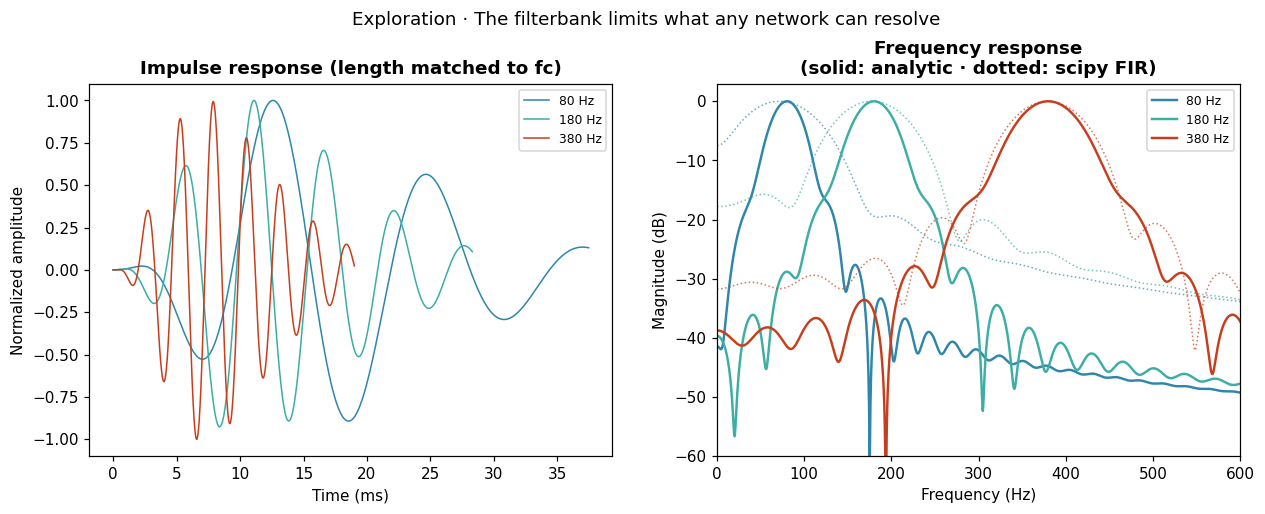

In [5]:
fig, ax = plt.subplots(1,2, figsize=(13.5,4.4))
for fc,c in zip([80,180,380],[BLUE,GREEN,RED]):
    h = A.impulse_response(fc)
    ax[0].plot(1000*np.arange(len(h))/A.SR, h/np.abs(h).max(), color=c, lw=1.0, label=f'{fc} Hz')
    w,H = freqz(h, worN=65536, fs=A.SR)
    ax[1].plot(w, 20*np.log10(np.abs(H)/np.abs(H).max()), color=c, lw=1.6, label=f'{fc} Hz')
    b_,a_ = gammatone(fc, ftype='fir', fs=A.SR, order=4)
    w2,H2 = freqz(b_,a_,worN=65536,fs=A.SR)
    ax[1].plot(w2, 20*np.log10(np.abs(H2)/np.abs(H2).max()), color=c, lw=1.0, ls=':', alpha=.7)
ax[0].set_xlabel('Time (ms)'); ax[0].set_ylabel('Normalized amplitude')
ax[0].set_title('Impulse response (length matched to fc)'); ax[0].legend(fontsize=8)
ax[1].set_xlim(0,600); ax[1].set_ylim(-60,3)
ax[1].set_xlabel('Frequency (Hz)'); ax[1].set_ylabel('Magnitude (dB)')
ax[1].set_title('Frequency response\n(solid: analytic · dotted: scipy FIR)')
ax[1].legend(fontsize=8)
fig.suptitle('Exploration · The filterbank limits what any network can resolve', y=1.03)
fig.savefig(FIGURES/'04-gammatone-filterbank.png'); plt.show()

**The whole argument, drawn.**

**Left panel: how long each channel listens.** This is the impulse response, how the filter rings after a single click and how long it takes to stop. The red curve (380 Hz) oscillates fast and dies out at 19.0 ms. The blue one (80 Hz) oscillates slowly and is still alive at 37.5 ms. That the three curves end at different times **is** the matched length: each channel gets the time it needs.

**Right panel: what each channel lets through.** The peak is the channel's note, and the slopes on either side are what it rejects. The **solid lines** are the analytic filterbank, three narrow peaks, each on its own frequency. The **dotted lines** are the `scipy` FIR filter, the same three peaks made wide and flat. Look at the region from 0 to 200 Hz. The solid blue and green curves are two separate peaks, while the corresponding dotted ones overlap.

**Conclusion of the section.** We adopt the analytic impulse response with a length matched to each channel. With it the sensory layer **does not solve the task on its own**. It reaches 0.223 or 0.250, depending on how the ceiling is measured, against a chance level of 0.200. That is what we need, so that whatever a network achieves above it can be attributed to the network. Section 5 measures the ceiling and explains the values.

## 3. The inner-hair-cell stage: from vibration to firing rate

### What we are building

Section 2 left **32 vibrating signals**. A neuron does not vibrate, though. It **fires**. This step translates vibration into *spikes per second*. In the mammalian ear this is the job of the **inner hair cell**, the receptor that the basilar membrane moves and that turns that motion into electrical activity. Our input stage is a generic model of an auditory periphery developed for the mammalian ear (gammatone filters, Hilbert envelope, rate-level function). The fly hears with Johnston's organ, not a cochlea, so the model borrows the processing steps, not the anatomy.

There are two steps, and in both the modeling choice matters for the same reason. A badly built encoder **lets regularities into the signal that are not the rhythm of the song**, and the classifier can exploit them. Accuracy would then rise for the wrong reason.

### Step 1 · The envelope: from oscillation to contour

The 250 Hz channel delivers something that goes up and down 250 times a second. What matters is not those oscillations but **how loud the channel is at each instant**, the contour that wraps them.

```
signal:    ∿∿∿∿∿∿∿∿∿∿∿∿∿     a click oscillating at its carrier
envelope:  ╭──────────╮       "there is sound here, this strong"
```

The obvious approach is **to average over a short window** of a few milliseconds, which is what an earlier version did, with 2 ms. The trouble is that **a moving average has blind spots**. A window of $T$ ms cancels exactly the frequencies that are multiples of $1000/T$ Hz.

The ripple we want to remove sits at **twice** the frequency of the channel. With $T = 2$ ms the blind spot falls exactly on $f_c = 250$ Hz, **the carrier of the song**. That frequency came out perfectly smooth while the others kept some ripple. The result was a systematic difference **between frequencies** that had nothing to do with tonotopy, the orderly mapping of frequency onto neurons. This blind spot is why we switched to the Hilbert envelope.

The **analytic (Hilbert) envelope** is the magnitude of the analytic signal, a standard way to separate envelope from fine structure in auditory models (Smith et al., 2002). It uses no window, so it has no blind spots and treats every frequency alike.

### Step 2 · From amplitude to rate: the rate-level function

The envelope is still an amplitude, and the neuron needs spikes per second. The conversion follows the S-shaped curve of an auditory-nerve fiber, as measured in the cat by Sachs and Abbas (1974), with its three stretches.

```
rate
  ▲        ╭──────────  saturation: more volume no longer raises the rate
  │      ╱
  │    ╱                 useful range (about 20 dB of dynamic range)
  │  ╱
  ├─╯                    threshold: below it, only spontaneous activity
  └──────────────► level (dB)
```

**The threshold is the key piece.** The earlier scheme compressed with a cube root, which squeezes five orders of magnitude of energy into fewer than two. After normalization, the floor swamps the profile, and channels that should stay silent add a pedestal. With a threshold, **channels far from the frequency of the tone stay at rest**, as a real fiber does.

The next cell measures both decisions.

In [6]:
# The two decisions of this section, checked
from scipy.signal import hilbert
import itertools

def ripple(env, f2, sr=A.SR):
    """How much carrier ripple survives in the envelope, measured at 2·fc."""
    t = np.arange(len(env)) / sr
    return float(np.abs((env * np.exp(-2j * np.pi * f2 * t)).sum()) / max(env.sum(), 1e-12))

def moving_average(y, ms):
    n = max(int(round(ms / 1000 * A.SR)), 1)
    return np.convolve(np.abs(y), np.ones(n) / n, mode='same')

print('1) ENVELOPE: carrier ripple that survives (0 = perfectly smoothed)\n')
print(f'{"tone (Hz)":>10}{"2 ms moving avg.":>19}{"Hilbert":>10}')
for f in [150, 170, 200, 220, 250, 300]:
    k = int(np.argmin(np.abs(A.CF - f)))
    y = A.gammatone_filterbank(A.tone(f))[k]
    print(f'{f:10d}{ripple(moving_average(y, 2), 2*f):19.3f}{ripple(np.abs(hilbert(y)), 2*f):10.3f}')
print('\n   A moving average of T ms cancels exactly the multiples of 1000/T Hz. The')
print('   ripple sits at 2·fc, so with T = 2 ms the blind spot falls on fc = 250 Hz,')
print('   the carrier of the song, and ripple survives at the other frequencies.')
print('   Hilbert uses no window and gives 0.000 everywhere.')

print('\n\n2) RATE-LEVEL: do the tones keep their spectral identity?\n')
tones = [100, 150, 200, 250, 300, 350]
cos = lambda a, b: float(a @ b / np.linalg.norm(a) / np.linalg.norm(b))
profiles = {}
for f in tones:
    e = A.envelope(A.gammatone_filterbank(A.tone(f)))
    c = e ** (1/3)
    profiles[f] = (A.inner_hair_cell(e).mean(axis=1), (c / c.mean()).mean(axis=1))
for j, name in enumerate(['sigmoid with threshold (used here)', 'cube root (earlier scheme)']):
    v = [cos(profiles[a][j], profiles[b][j]) for a, b in itertools.combinations(tones, 2)]
    extreme_cos = cos(profiles[100][j], profiles[350][j])
    print(f'   {name:36s} mean cosine {np.mean(v):.3f}   100 vs 350 Hz: {extreme_cos:.3f}')
print('\n   With the cube root the mean similarity between different tones doubles and')
print('   no pair falls below 0.475, because the floor dominates the profile. With a')
print('   threshold, the channels far from the tone frequency stay at rest and the two')
print('   ends of the filterbank separate almost completely.')


1) ENVELOPE: carrier ripple that survives (0 = perfectly smoothed)

 tone (Hz)   2 ms moving avg.   Hilbert
       150              0.169     0.000
       170              0.133     0.000
       200              0.079     0.000
       220              0.045     0.000
       250              0.001     0.000
       300              0.052     0.000

   A moving average of T ms cancels exactly the multiples of 1000/T Hz. The
   ripple sits at 2·fc, so with T = 2 ms the blind spot falls on fc = 250 Hz,
   the carrier of the song, and ripple survives at the other frequencies.
   Hilbert uses no window and gives 0.000 everywhere.


2) RATE-LEVEL: do the tones keep their spectral identity?



   sigmoid with threshold (used here)   mean cosine 0.301   100 vs 350 Hz: 0.005
   cube root (earlier scheme)           mean cosine 0.705   100 vs 350 Hz: 0.475

   With the cube root the mean similarity between different tones doubles and
   no pair falls below 0.475, because the floor dominates the profile. With a
   threshold, the channels far from the tone frequency stay at rest and the two
   ends of the filterbank separate almost completely.


**Both checks confirm both decisions.**

**The envelope.** The 2 ms moving average lets ripple through at almost every frequency (0.169 at 150 Hz, 0.133 at 170 Hz, 0.052 at 300 Hz) and cancels it **only at 250 Hz**, with 0.001. That the blind spot coincides with the carrier of the song is the worst possible case. The stimulus frequency itself would be treated differently from all the others, by an accident of the smoothing. Hilbert gives **0.000 in all six**.

**The rate-level function.** With the cube root, the mean similarity between different tones is **0.705**, and the two most distant tones tested, 100 and 350 Hz, still have a similarity of **0.475**. The floor dominates and the tones lose their identity. With the sigmoid and its threshold, the mean similarity drops to **0.301** and that same pair falls to **0.005**, practically orthogonal. The excitation profile gets its shape back.

The next cell draws the whole chain on a real song.

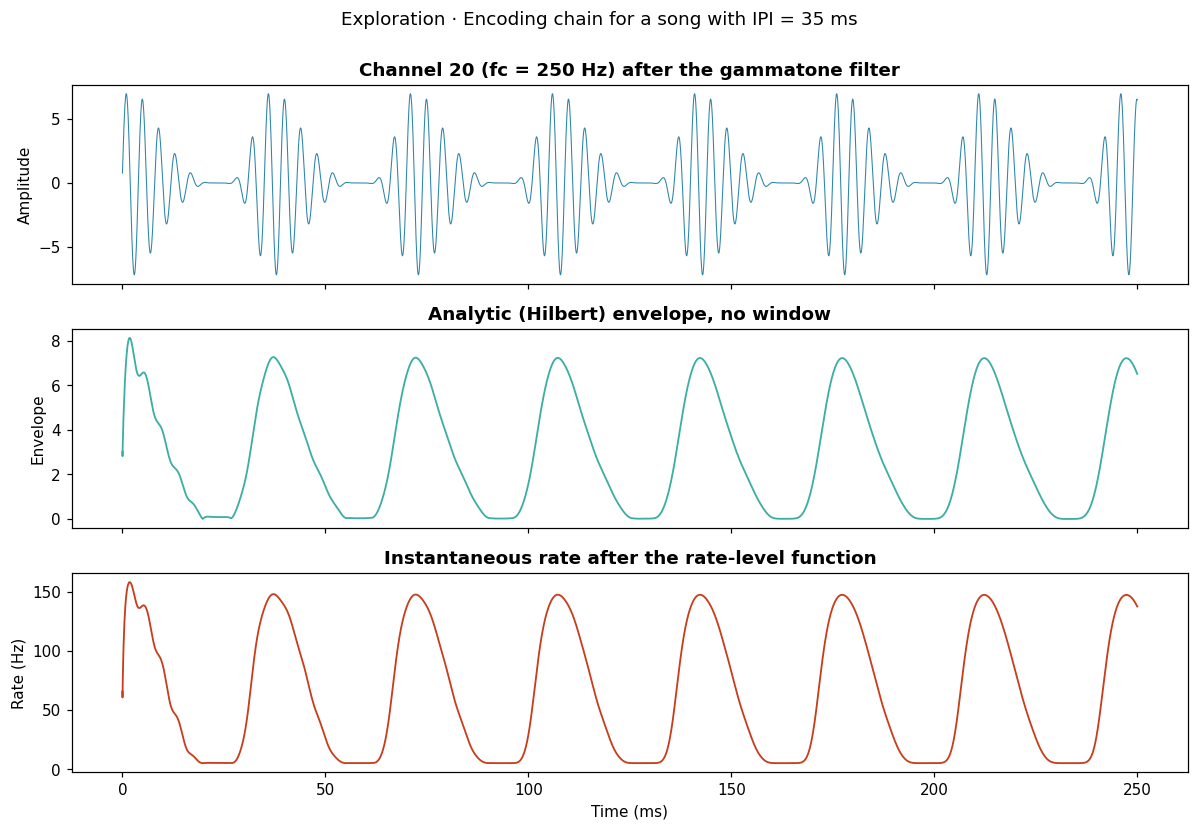

In [7]:
ipi_demo = 35
y = A.gammatone_filterbank(A.pulse_song(ipi_demo))
env = A.envelope(y)
act = A.inner_hair_cell(env)
rates = A.envelope_to_rates(act)

fig, ax = plt.subplots(3,1, figsize=(11,7.5), sharex=True)
k = int(np.argmin(np.abs(A.CF-A.SONG_CARRIER_HZ)))
t_ms = 1000*np.arange(y.shape[1])/A.SR; m = t_ms<=250
ax[0].plot(t_ms[m], y[k][m], lw=.7, color=BLUE)
ax[0].set_ylabel('Amplitude'); ax[0].set_title(f'Channel {k} (fc = {A.CF[k]:.0f} Hz) after the gammatone filter')
ax[1].plot(t_ms[m], env[k][m], lw=1.2, color=GREEN)
ax[1].set_ylabel('Envelope'); ax[1].set_title('Analytic (Hilbert) envelope, no window')
ax[2].plot(t_ms[m], rates[k][m], lw=1.2, color=RED)
ax[2].set_ylabel('Rate (Hz)'); ax[2].set_xlabel('Time (ms)')
ax[2].set_title('Instantaneous rate after the rate-level function')
fig.suptitle(f'Exploration · Encoding chain for a song with IPI = {ipi_demo} ms', y=1.0)
fig.tight_layout(); fig.savefig(FIGURES/'04-inner-hair-cell-chain.png'); plt.show()

The figure follows channel 20, whose center frequency (250 Hz) matches the carrier, through the first 250 ms of a song with IPI = 35 ms. The top panel is the output of the gammatone filter, one burst of ringing per song pulse. The middle panel is its Hilbert envelope, a smooth bump per pulse with no carrier ripple left. The bottom panel is the instantaneous firing rate after the rate-level function. Between pulses the rate falls to the spontaneous level of 5 Hz, and during each pulse it climbs steeply. That alternation is the rhythm the network will have to read.

## 4. From rates to spikes: an inhomogeneous Poisson process

Each neuron of the input layer receives the instantaneous rate of its channel and fires according to an **inhomogeneous Poisson process**, a way of drawing spikes at random with a rate that changes over time (Dayan & Abbott, 2001). The draw runs in steps of 0.1 ms, the same time step as the network simulation.

**How channels are assigned to neurons.** The default mapping is **anchored to anatomy**. Phase 02 recovered the cell subtype of each input neuron, 87 JO-B and 36 JO-A, and the subtype decides which block of channels each neuron receives. JO-A and JO-B are the vibration-sensitive subgroups of Johnston's organ. JO-B prefers low-frequency vibration, below about 100 Hz, while JO-A carries the high-frequency responses (Kamikouchi et al., 2009; Matsuo et al., 2014). We therefore give the low channels to the JO-B neurons and the high channels to the JO-A neurons. This is only a coarse, two-level anchor. Within each subtype the order is arbitrary (by FlyWire identifier, `root_id`). This is the `subtype` mode used in the next cell.

The ordering by `root_id` that an earlier version used remains as one of the three alternatives to the anchored mapping, together with the inverted anchoring and a random assignment. The four are compared in Section 3 of the [static-connectome notebook](03-connectome-static.ipynb) and in Section 6 of the [connectome-with-STDP notebook](04-connectome-stdp.ipynb).

**Seeds.** The seed of the Poisson draw and the seed of the timing jitter of the song pulses depend on the **repetition**, never on the class. If each class had its own seed, two identical stimuli would give different responses only because of the draw, and that difference would pass for discrimination. Sharing the realization keeps the comparison paired.

In [8]:
Cg = graph.load()
mapping = Cg.channel_map(A.N_CHANNELS, mode='subtype')
print(f'Input layer: {Cg.N_input} neurons → {A.N_CHANNELS} channels')
counts = np.bincount(mapping, minlength=A.N_CHANNELS)
print(f'Neurons per channel: minimum {counts.min()}, maximum {counts.max()}')
print(f'Subtype: ' + str(dict(zip(*np.unique(Cg.input_type, return_counts=True)))))
print()
print('Realizations of the same song with different seeds:')
for s_ in range(3):
    T = A.song_rates(35, jitter_seed=s_)
    i_, t_ = A.spike_trains(T, mapping, seed=s_)
    print(f'  seed {s_}: {len(i_):,} spikes')
print('\nSame draw, different classes (paired comparison):')
for ipi in [25, 65]:
    T = A.song_rates(ipi, jitter_seed=0)
    i_, t_ = A.spike_trains(T, mapping, seed=0)
    print(f'  IPI {ipi} ms, seed 0: {len(i_):,} spikes')

Input layer: 123 neurons → 32 channels
Neurons per channel: minimum 3, maximum 4
Subtype: {'JO-A': np.int64(36), 'JO-B': np.int64(87)}

Realizations of the same song with different seeds:
  seed 0: 2,412 spikes
  seed 1: 2,434 spikes
  seed 2: 2,462 spikes

Same draw, different classes (paired comparison):
  IPI 25 ms, seed 0: 2,457 spikes
  IPI 65 ms, seed 0: 2,430 spikes


Each of the 32 channels drives 3 or 4 input neurons. The same song drawn with seeds 0, 1 and 2 gives 2,412, 2,434 and 2,462 input spikes. With the same seed, the songs at 25 and 65 ms give 2,457 and 2,430 spikes. The difference between classes is no larger than the difference between draws of one class, so the total spike count carries no information about the class.

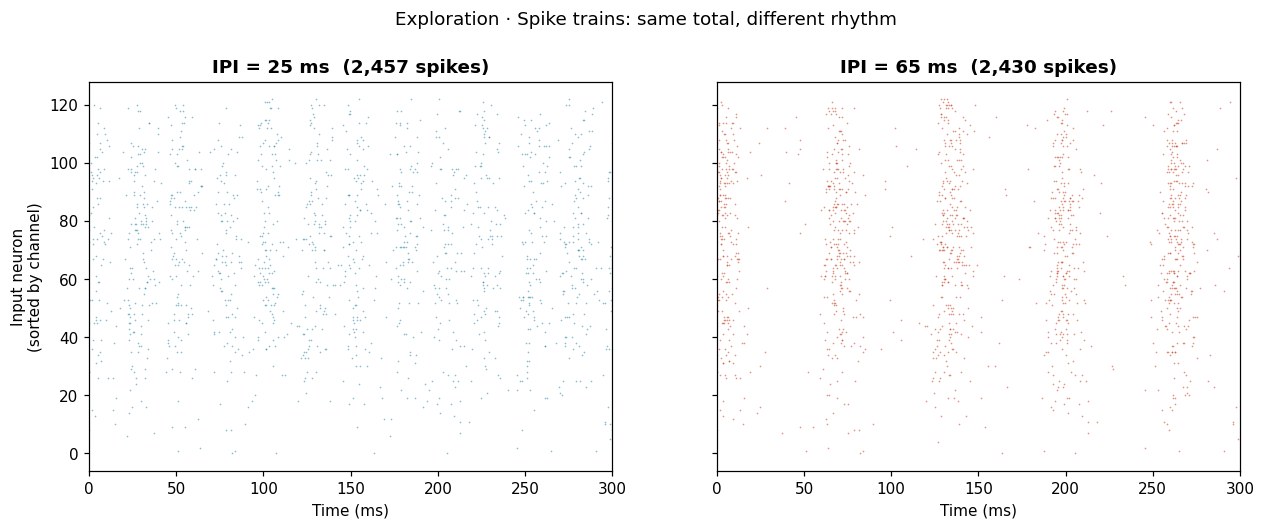

In [9]:
fig, ax = plt.subplots(1,2, figsize=(13.5,4.6), sharey=True)
for a, ipi, c in zip(ax, [25, 65], [BLUE, RED]):
    T = A.song_rates(ipi, jitter_seed=0)
    i_, t_ = A.spike_trains(T, mapping, seed=0)
    order = np.argsort(mapping, kind='stable')
    pos = np.empty_like(order); pos[order] = np.arange(len(order))
    a.scatter(t_, pos[i_], s=1.2, c=c, alpha=.55, linewidths=0)
    a.set_xlabel('Time (ms)'); a.set_title(f'IPI = {ipi} ms  ({len(i_):,} spikes)')
    a.set_xlim(0, 300)
ax[0].set_ylabel('Input neuron\n(sorted by channel)')
fig.suptitle('Exploration · Spike trains: same total, different rhythm', y=1.02)
fig.savefig(FIGURES/'04-input-spike-raster.png'); plt.show()

The two rasters (2,457 and 2,430 spikes) use the same band of active channels. Only the spacing between bursts differs. That is all the information the network receives.

## 5. The ceiling of the task: how much information is already in the input?

This is the most important check of the notebook, and the one that led to changing the task.

If the input layer already solves the task, the networks can only degrade that information, and the comparison between wirings no longer measures computing ability. We check it by training the same linear readout directly on the spike counts of the 123 JO neurons, with no network in between.

**About the number this cell gives.** The cell measures the ceiling once, with 20 presentations per class and a fixed pair of seed ranges, and obtains **0.250**. The reports quote **0.223** and **0.226**. Those are the same ceiling measured inside every run of the experiment and then averaged, 0.226 over the five seeds of the static arms and 0.223 over all sixty runs. The three values say the same thing, that the input barely beats the chance level of 0.200. The differences between them are estimation noise from small samples, not a disagreement.

First come the two conditions that make the task fair: the same spike budget and the same spectrum for every song.

In [10]:
print(f'{"IPI":>5}{"mean rate":>13}{"max rate":>11}{"pulses":>9}')
profiles={}
for ipi in IPIS:
    T = A.song_rates(ipi, jitter_seed=0)
    profiles[ipi] = T.mean(axis=1)
    print(f'{ipi:5d}{T.mean():11.2f} Hz{T.max():9.1f} Hz{int(A.DURATION*1000/ipi):9d}')
print()
print('The mean rate is identical in all five songs, so the class cannot be inferred')
print('from the total count of input spikes.')
print()
print('Spectral overlap between classes (cosine of the per-channel profile):')
for b in IPIS[1:]:
    u,v = profiles[IPIS[0]], profiles[b]
    print(f'  IPI {IPIS[0]} vs {b}: {u@v/np.linalg.norm(u)/np.linalg.norm(v):.5f}')
print()
print('The spectra are indistinguishable. The songs share the carrier, and the interval')
print('between pulses does not show up in the per-channel profile. The information is')
print('ONLY in time, so the network has to turn it into a rate before it can be read out.')

  IPI    mean rate   max rate   pulses
   25      40.00 Hz    115.8 Hz       20
   35      40.00 Hz    151.3 Hz       14
   45      40.00 Hz    207.2 Hz       11
   55      40.00 Hz    253.3 Hz        9
   65      40.00 Hz    285.3 Hz        7

The mean rate is identical in all five songs, so the class cannot be inferred
from the total count of input spikes.

Spectral overlap between classes (cosine of the per-channel profile):
  IPI 25 vs 35: 0.99996
  IPI 25 vs 45: 0.99996
  IPI 25 vs 55: 0.99996
  IPI 25 vs 65: 0.99996

The spectra are indistinguishable. The songs share the carrier, and the interval
between pulses does not show up in the per-channel profile. The information is
ONLY in time, so the network has to turn it into a rate before it can be read out.


The mean rate is 40.00 Hz for all five songs, so the expected number of input spikes is the same. Only the peak rate changes (from 115.8 Hz at 25 ms to 285.3 Hz at 65 ms), because a sparser song concentrates the same spikes into fewer, stronger bursts. The cosine between the per-channel profiles of the 25 ms song and each of the other four is 0.99996, which means their spectra are practically the same.

### Measuring the ceiling

The readout is the one used in every experiment: the spike counts of each neuron are standardized and fed to a logistic regression (Pedregosa et al., 2011). It is trained on 20 presentations of each song and tested on 20 new ones, drawn with seeds that never overlap with the training seeds. It counts the spikes of each neuron over the whole presentation, with no temporal resolution; a readout that saw the timing could read the interval directly from the input.

Accuracy reading ONLY the input layer: 0.250
Chance:                                0.200
Headroom left for the network:         0.750

With the earlier pure-tone task this same measurement gave 1.000: the input
solved everything and left no headroom. Now the input barely beats chance,
so any accuracy above that value is computation done by the network.


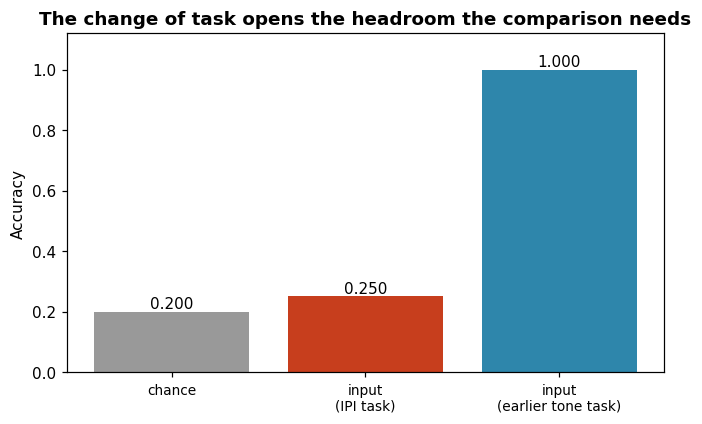

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

Cg = graph.load()
mapping = Cg.channel_map(A.N_CHANNELS, mode='subtype')

def input_counts(n_rep, base_seed):
    X, y = [], []
    for r in range(n_rep):
        for ipi in IPIS:
            T = A.song_rates(ipi, jitter_seed=base_seed+r, jitter_ms=JITTER_MS)
            i_, t_ = A.spike_trains(T, mapping, seed=base_seed+r)
            X.append(np.bincount(i_, minlength=Cg.N_input)); y.append(ipi)
    return np.array(X, float), np.array(y)

Xtr, ytr = input_counts(20, 0)
Xte, yte = input_counts(20, 5000)
readout = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
ceiling = readout.fit(Xtr, ytr).score(Xte, yte)
print(f'Accuracy reading ONLY the input layer: {ceiling:.3f}')
print(f'Chance:                                {1/len(IPIS):.3f}')
print(f'Headroom left for the network:         {1-ceiling:.3f}')
print()
print('With the earlier pure-tone task this same measurement gave 1.000: the input')
print('solved everything and left no headroom. Now the input barely beats chance,')
print('so any accuracy above that value is computation done by the network.')

fig, ax = plt.subplots(figsize=(7,4))
ax.bar([0,1,2], [1/len(IPIS), ceiling, 1.0], color=[GRAY if 'GRAY' in dir() else '#999999', RED, BLUE])
ax.set_xticks([0,1,2])
ax.set_xticklabels(['chance', 'input\n(IPI task)', 'input\n(earlier tone task)'], fontsize=9)
ax.set_ylabel('Accuracy'); ax.set_ylim(0,1.12)
ax.set_title('The change of task opens the headroom the comparison needs')
for i_,v_ in enumerate([1/len(IPIS), ceiling, 1.0]):
    ax.text(i_, v_, f'{v_:.3f}', ha='center', va='bottom', fontsize=10)
fig.savefig(FIGURES/'04-input-only-ceiling.png'); plt.show()

Reading only the input layer, the readout reaches **0.250**, against a chance level of **0.200**. The headroom left for a network is 0.750, and any accuracy above the ceiling is computation done by the network.

The third bar is the same measurement made on the earlier tone task, where the input layer alone scored 1.000. That value is written into the cell by hand. It comes from an earlier version of the project, and this repository no longer runs the tone task. We keep it in the figure because the contrast between the two bars is the reason for the change of task.

The spectral overlap is 0.99996 between the 25 ms song and each of the others, so the songs are indistinguishable by their frequency content. All the information about the class is in the rhythm, and the networks of notebooks 2 to 4 have to turn that rhythm into differences in firing rate before the readout can use it.

## References

- Baker, C. A., McKellar, C., Pang, R., Nern, A., Dorkenwald, S., Pacheco, D. A., Eckstein, N., Funke, J., Dickson, B. J., & Murthy, M. (2022). Neural network organization for courtship-song feature detection in *Drosophila*. *Current Biology, 32*(15), 3317–3333.e7. https://doi.org/10.1016/j.cub.2022.06.019
- Bennet-Clark, H. C., & Ewing, A. W. (1969). Pulse interval as a critical parameter in the courtship song of *Drosophila melanogaster*. *Animal Behaviour, 17*(4), 755–759. https://doi.org/10.1016/S0003-3472(69)80023-0
- Chapman, P., Clinton, J., Kerber, R., Khabaza, T., Reinartz, T., Shearer, C., & Wirth, R. (2000). *CRISP-DM 1.0: Step-by-step data mining guide*. SPSS Inc. https://web.archive.org/web/20060207174803/http://www.crisp-dm.org/CRISPWP-0800.pdf
- Clemens, J., Coen, P., Roemschied, F. A., Pereira, T. D., Mazumder, D., Aldarondo, D. E., Pacheco, D. A., & Murthy, M. (2018). Discovery of a new song mode in *Drosophila* reveals hidden structure in the sensory and neural drivers of behavior. *Current Biology, 28*(15), 2400–2412.e6. https://doi.org/10.1016/j.cub.2018.06.011
- Cohen, J. (2013). *Statistical power analysis for the behavioral sciences* (2nd ed.). Routledge. https://doi.org/10.4324/9780203771587 (Original work published 1988)
- Dayan, P., & Abbott, L. F. (2001). *Theoretical neuroscience: Computational and mathematical modeling of neural systems*. MIT Press. https://mitpress.mit.edu/9780262041997/theoretical-neuroscience/
- Deutsch, D., Clemens, J., Thiberge, S. Y., Guan, G., & Murthy, M. (2019). Shared song detector neurons in *Drosophila* male and female brains drive sex-specific behaviors. *Current Biology, 29*(19), 3200–3215.e5. https://doi.org/10.1016/j.cub.2019.08.008
- Dorkenwald, S., Matsliah, A., Sterling, A. R., Schlegel, P., Yu, S.-c., McKellar, C. E., Lin, A., Costa, M., Eichler, K., Yin, Y., Silversmith, W., Schneider-Mizell, C., Jordan, C. S., Brittain, D., Halageri, A., Kuehner, K., Ogedengbe, O., Morey, R., Gager, J., . . . The FlyWire Consortium. (2024). Neuronal wiring diagram of an adult brain. *Nature, 634*(8032), 124–138. https://doi.org/10.1038/s41586-024-07558-y
- Fayyad, U., Piatetsky-Shapiro, G., & Smyth, P. (1996). From data mining to knowledge discovery in databases. *AI Magazine, 17*(3), 37–54. https://doi.org/10.1609/aimag.v17i3.1230
- Gibbon, J. (1977). Scalar expectancy theory and Weber’s law in animal timing. *Psychological Review, 84*(3), 279–325. https://doi.org/10.1037/0033-295X.84.3.279
- Glasberg, B. R., & Moore, B. C. J. (1990). Derivation of auditory filter shapes from notched-noise data. *Hearing Research, 47*(1–2), 103–138. https://doi.org/10.1016/0378-5955(90)90170-T
- Holdsworth, J., Patterson, R., Nimmo-Smith, I., & Rice, P. (1988). *Implementing a GammaTone filter bank* (Annex C of the SVOS Final Report, Part A: The Auditory Filterbank). MRC Applied Psychology Unit. https://www.pdn.cam.ac.uk/system/files/documents/SVOSAnnexC1988.pdf
- Kamikouchi, A., Inagaki, H. K., Effertz, T., Hendrich, O., Fiala, A., Göpfert, M. C., & Ito, K. (2009). The neural basis of *Drosophila* gravity-sensing and hearing. *Nature, 458*(7235), 165–171. https://doi.org/10.1038/nature07810
- Kyriacou, C. P., & Hall, J. C. (1980). Circadian rhythm mutations in *Drosophila melanogaster* affect short-term fluctuations in the male’s courtship song. *Proceedings of the National Academy of Sciences, 77*(11), 6729–6733. https://doi.org/10.1073/pnas.77.11.6729
- Matsuo, E., Yamada, D., Ishikawa, Y., Asai, T., Ishimoto, H., & Kamikouchi, A. (2014). Identification of novel vibration- and deflection-sensitive neuronal subgroups in Johnston’s organ of the fruit fly. *Frontiers in Physiology, 5*, Article 179. https://doi.org/10.3389/fphys.2014.00179
- Patterson, R. D., Robinson, K., Holdsworth, J., McKeown, D., Zhang, C., & Allerhand, M. (1992). Complex sounds and auditory images. In Y. Cazals, L. Demany, & K. Horner (Eds.), *Auditory physiology and perception* (pp. 429–446). Pergamon. https://doi.org/10.1016/B978-0-08-041847-6.50054-X
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830. https://jmlr.org/papers/v12/pedregosa11a.html
- Sachs, M. B., & Abbas, P. J. (1974). Rate versus level functions for auditory-nerve fibers in cats: Tone-burst stimuli. *The Journal of the Acoustical Society of America, 56*(6), 1835–1847. https://doi.org/10.1121/1.1903521
- Slaney, M. (1993). *An efficient implementation of the Patterson–Holdsworth auditory filter bank* (Apple Computer Technical Report No. 35). Apple Computer. https://engineering.purdue.edu/~malcolm/apple/tr35/PattersonsEar.pdf
- Smith, Z. M., Delgutte, B., & Oxenham, A. J. (2002). Chimaeric sounds reveal dichotomies in auditory perception. *Nature, 416*(6876), 87–90. https://doi.org/10.1038/416087a
- Song, S., Miller, K. D., & Abbott, L. F. (2000). Competitive Hebbian learning through spike-timing-dependent synaptic plasticity. *Nature Neuroscience, 3*(9), 919–926. https://doi.org/10.1038/78829
- Virtanen, P., Gommers, R., Oliphant, T. E., Haberland, M., Reddy, T., Cournapeau, D., Burovski, E., Peterson, P., Weckesser, W., Bright, J., van der Walt, S. J., Brett, M., Wilson, J., Millman, K. J., Mayorov, N., Nelson, A. R. J., Jones, E., Kern, R., Larson, E., . . . Vázquez-Baeza, Y. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. *Nature Methods, 17*(3), 261–272. https://doi.org/10.1038/s41592-019-0686-2
- Zhou, C., Franconville, R., Vaughan, A. G., Robinett, C. C., Jayaraman, V., & Baker, B. S. (2015). Central neural circuitry mediating courtship song perception in male *Drosophila*. *eLife, 4*, Article e08477. https://doi.org/10.7554/eLife.08477